## History Lesson

In [2]:

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day

from datetime import date
from quantdata.yahoo.client import YFClient
from quantdata.biz_calendar import next_business_day, count_business_days_between
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context
from IPython.display import display

def test():
    ticker = "^SPX"
    d      = next_business_day( date(2020, 1, 2), count_start=True )
    e      = next_business_day( date(2026, 7, 15), count_start=True )
    data   = YFClient().prices(ticker, d, e)

    display(data)
    return ticker, data

ticker, history = test()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Price,Close,Dividends,High,Low,Open,Stock Splits,Volume
2020-01-02,3257.850098,0.0,3258.139893,3235.530029,3244.669922,0.0,3.459930e+09
2020-01-03,3234.850098,0.0,3246.149902,3222.340088,3226.360107,0.0,3.484700e+09
2020-01-06,3246.280029,0.0,3246.840088,3214.639893,3217.550049,0.0,3.702460e+09
2020-01-07,3237.179932,0.0,3244.909912,3232.429932,3241.860107,0.0,3.435910e+09
2020-01-08,3253.050049,0.0,3267.070068,3236.669922,3238.590088,0.0,3.726840e+09
...,...,...,...,...,...,...,...
2026-07-08,7482.709961,0.0,7488.509766,7421.819824,7476.540039,0.0,5.102020e+09
2026-07-09,7543.640137,0.0,7546.890137,7481.729980,7491.600098,0.0,4.442950e+09
2026-07-10,7575.390137,0.0,7579.930176,7508.160156,7547.640137,0.0,4.006370e+09
2026-07-13,7515.339844,0.0,7565.370117,7506.410156,7547.529785,0.0,4.729990e+09


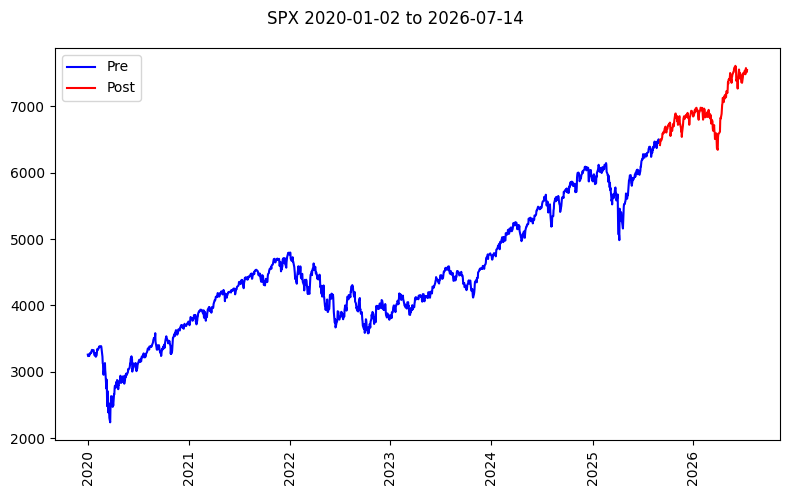

In [8]:
from cdxcore.dynaplot import figure
from datetime import datetime as dt

def plot():
    start = history.index[0]
    end   = history.index[-1]
    cut_off = dt(2025,8,30)
    pre  = history.index < cut_off
    post = history.index >= cut_off


    with figure(f"{ticker[1:]} {start.date()} to {end.date()}", figsize=(8, 5)) as fig:
        ax = fig.add_subplot()
        ax.plot( history.index[pre], history['Close'][pre], label='Pre', color='blue' )
        ax.plot( history.index[post], history['Close'][post], label='Post', color='red' )
        ax.tick_params(axis="x", labelrotation=90)
        ax.legend(loc="upper left")

plot()